# 04 · Reviews: 5.000 review được giao

Reviews là đầu vào duy nhất cho phần LLM (cảm xúc, khía cạnh và ngôn ngữ) và cho bộ 100 nhãn tay. Trước khi viết prompt, nhóm cần biết các
review này dài bao nhiêu, được viết vào thời gian nào và có ký tự lạ không. Câu hỏi quan trọng nhất là reviews của bốn mốc có thật sự là bốn
bộ ý kiến khác nhau hay không.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

TEN_CAU_HINH = "london.yaml"   # Đổi file cấu hình ở đây nếu khảo sát thành phố/mốc khác.


def tim_thu_muc_du_an(thu_muc_bat_dau: Path) -> Path:
    """Đi ngược lên các thư mục cha cho tới khi gặp configs/<TEN_CAU_HINH>."""
    # Vòng lặp qua các thư mục cha (vài cấp), không phải qua dòng dữ liệu.
    for thu_muc in [thu_muc_bat_dau, *thu_muc_bat_dau.parents]:
        if (thu_muc / "configs" / TEN_CAU_HINH).is_file():
            return thu_muc

    raise FileNotFoundError(f"Không tìm thấy thư mục dự án chứa configs/{TEN_CAU_HINH}")


THU_MUC_DU_AN = tim_thu_muc_du_an(Path.cwd().resolve())

with (THU_MUC_DU_AN / "configs" / TEN_CAU_HINH).open("r", encoding="utf-8-sig") as f:
    cau_hinh = yaml.safe_load(f)

thanh_pho = cau_hinh["city"]
snapshots = [str(snapshot) for snapshot in cau_hinh["snapshots"]]   # YAML đọc ngày không nháy thành date
moc_gia = max(snapshots)   # Quy tắc của nhóm: chỉ mốc cuối được dùng giá
THU_MUC_RAW = THU_MUC_DU_AN / "data" / "raw" / thanh_pho
THU_MUC_PHAN_CONG = THU_MUC_DU_AN / "data" / "assignment"

phan_cong_listings = pd.read_csv(THU_MUC_PHAN_CONG / "listings.csv", dtype=str, keep_default_na=False)
phan_cong_reviews = pd.read_csv(THU_MUC_PHAN_CONG / "reviews.csv", dtype=str, keep_default_na=False)
phan_cong_vung = pd.read_csv(THU_MUC_PHAN_CONG / "areas.csv", dtype={"analysis_area": str}, keep_default_na=False)
cac_listing_id = set(phan_cong_listings["listing_id"])
cac_review_id = set(phan_cong_reviews["review_id"])

print("Thư mục dự án :", THU_MUC_DU_AN.name)
print("Thành phố     :", thanh_pho, "| tiền tệ:", cau_hinh["currency"])
print("Các mốc       :", snapshots, "| mốc dùng giá:", moc_gia)
print("Phân công     :", len(cac_listing_id), "listing,", len(cac_review_id), "review")

Thư mục dự án : 2627-LTXLDL-Airbnb-dse2049_7-nhom15
Thành phố     : london | tiền tệ: GBP
Các mốc       : ['2025-09-14', '2025-12-13', '2026-03-21', '2026-06-19'] | mốc dùng giá: 2026-06-19
Phân công     : 1000 listing, 5000 review


## 1. Lọc đúng 5.000 review được giao

Ô dưới đây lọc theo cột `id` của reviews, tức là mã review, khớp với `review_id` trong file phân công. Để so sánh, nó cũng đếm số dòng sẽ giữ
lại nếu lọc nhầm theo `listing_id`, cùng tổng số review, ngày review mới nhất, tỷ lệ review ngắn hơn 64 ký tự và tổng số ký tự của cả thành phố. Ô này chạy mất khoảng một đến hai phút.

In [2]:
reviews_nhom: dict[str, pd.DataFrame] = {}
thong_tin_doc: dict[str, dict] = {}

# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    cac_khoi_da_loc = []
    so_dong_thanh_pho = 0
    so_dong_neu_loc_theo_listing = 0
    so_review_duoi_64_ky_tu = 0
    tong_ky_tu = 0
    ngay_moi_nhat = ""
    with pd.read_csv(THU_MUC_RAW / snapshot / "reviews.csv.gz", dtype=str, keep_default_na=False, chunksize=300_000) as cac_khoi:
        # Vòng lặp qua các khối 300 nghìn dòng: file reviews hơn 1 GB khi giải nén (Bài 6).
        for khoi in cac_khoi:
            do_dai = khoi["comments"].str.len()
            so_dong_thanh_pho += len(khoi)
            so_dong_neu_loc_theo_listing += int(khoi["listing_id"].isin(cac_listing_id).sum())
            so_review_duoi_64_ky_tu += int(do_dai.lt(64).sum())
            tong_ky_tu += int(do_dai.sum())
            ngay_moi_nhat = max(ngay_moi_nhat, khoi["date"].max())
            cac_khoi_da_loc.append(khoi.loc[khoi["id"].isin(cac_review_id)])

    reviews_nhom[snapshot] = pd.concat(cac_khoi_da_loc, ignore_index=True).set_index("id")
    thong_tin_doc[snapshot] = {
        "review_thanh_pho": so_dong_thanh_pho,
        "neu_loc_theo_listing_id": so_dong_neu_loc_theo_listing,
        "loc_dung_theo_review_id": len(reviews_nhom[snapshot]),
        "review_moi_nhat_thanh_pho": ngay_moi_nhat,
        "%_review_duoi_64_ky_tu": round(100 * so_review_duoi_64_ky_tu / so_dong_thanh_pho, 1),
        "tong_ky_tu_comments": tong_ky_tu,
    }
    print(f"[ĐÃ LỌC] {snapshot}", flush=True)

pd.DataFrame(thong_tin_doc).T

[ĐÃ LỌC] 2025-09-14


[ĐÃ LỌC] 2025-12-13


[ĐÃ LỌC] 2026-03-21


[ĐÃ LỌC] 2026-06-19


,review_thanh_pho,neu_loc_theo_listing_id,loc_dung_theo_review_id,review_moi_nhat_thanh_pho,%_review_duoi_64_ky_tu,tong_ky_tu_comments
2025-09-14,2097996,37302,5000,2025-09-17,17.2,515838746
2025-12-13,2121675,40709,5000,2026-01-01,17.3,520797268
2026-03-21,1600972,43508,5000,2026-04-02,17.9,388117206
2026-06-19,2241353,46687,5000,2026-06-30,17.5,548956753


Cột `neu_loc_theo_listing_id` cho thấy vì sao phải lọc theo `review_id`. Nếu lọc theo listing, nhóm sẽ giữ từ 37 đến 47 nghìn review, tức toàn bộ lịch sử
review của 1.000 chỗ ở, thay vì 5.000 review đã được chọn.

Cột `review_thanh_pho` lại cho thấy vấn đề của mốc 2026-03-21. Mốc này chỉ có 1,6 triệu review, trong khi các mốc khác có từ 2,1 đến 2,2 triệu. Review
là dữ liệu cộng dồn nên tổng số review lẽ ra không giảm. Mức giảm này đi cùng mức giảm số listing ở notebook 02, nhưng dữ liệu không cho biết
nguyên nhân. Hai cột cuối được dùng ở mục 3 và mục 7.

In [3]:
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, reviews in reviews_nhom.items():
    doi_chieu = reviews.join(phan_cong_reviews.set_index("review_id")[["listing_id"]], rsuffix="_phan_cong")
    print(f"{snapshot}: thiếu ID = {len(cac_review_id - set(reviews.index))}, trùng ID = {reviews.index.duplicated().sum()}, "
          f"listing_id lệch phân công = {(doi_chieu['listing_id'] != doi_chieu['listing_id_phan_cong']).sum()}, "
          f"comments rỗng = {reviews['comments'].str.strip().eq('').sum()}")

2025-09-14: thiếu ID = 0, trùng ID = 0, listing_id lệch phân công = 0, comments rỗng = 0
2025-12-13: thiếu ID = 0, trùng ID = 0, listing_id lệch phân công = 0, comments rỗng = 0
2026-03-21: thiếu ID = 0, trùng ID = 0, listing_id lệch phân công = 0, comments rỗng = 0
2026-06-19: thiếu ID = 0, trùng ID = 0, listing_id lệch phân công = 0, comments rỗng = 0


Ở cả bốn mốc, không review nào bị thiếu hay trùng, mỗi review đều thuộc đúng listing ghi trong file phân công, và không có nội dung rỗng.

## 2. So nội dung review giữa các mốc

In [4]:
moc_dau = reviews_nhom[snapshots[0]]
# Vòng lặp qua 3 mốc sau để so với mốc đầu; phép so sánh chạy trên cả cột.
for snapshot in snapshots[1:]:
    sau = reviews_nhom[snapshot].loc[moc_dau.index]
    print(f"{snapshots[0]} → {snapshot}: comments giống hệt {int((sau['comments'] == moc_dau['comments']).sum())}/5000, "
          f"date giống hệt {int((sau['date'] == moc_dau['date']).sum())}/5000, "
          f"listing_id giống hệt {int((sau['listing_id'] == moc_dau['listing_id']).sum())}/5000")

# Chỉ đếm số dòng khác nhau, không in tên người viết để tránh hiển thị dữ liệu cá nhân.
sau = reviews_nhom[moc_gia].loc[moc_dau.index]
print(f"\nreviewer_id khác giữa {snapshots[0]} và {moc_gia}: {int((sau['reviewer_id'] != moc_dau['reviewer_id']).sum())}, "
      f"reviewer_name khác: {int((sau['reviewer_name'] != moc_dau['reviewer_name']).sum())}")

ngay_review = pd.to_datetime(reviews_nhom[moc_gia]["date"])
print("Review cũ nhất:", ngay_review.min().date(), "| mới nhất:", ngay_review.max().date())

2025-09-14 → 2025-12-13: comments giống hệt 5000/5000, date giống hệt 5000/5000, listing_id giống hệt 5000/5000
2025-09-14 → 2026-03-21: comments giống hệt 5000/5000, date giống hệt 5000/5000, listing_id giống hệt 5000/5000
2025-09-14 → 2026-06-19: comments giống hệt 5000/5000, date giống hệt 5000/5000, listing_id giống hệt 5000/5000

reviewer_id khác giữa 2025-09-14 và 2026-06-19: 0, reviewer_name khác: 24
Review cũ nhất: 2011-10-06 | mới nhất: 2025-09-15


Bốn mốc chứa cùng 5.000 review, với cùng listing, cùng nội dung và cùng ngày viết. Chỉ có tên hiển thị của người viết khác ở 24 review khi so mốc đầu với mốc cuối,
trong khi mã người viết (`reviewer_id`) không đổi. Review mới nhất được viết ngày 15/9/2025, ngay sau mốc đầu tiên.
Dữ liệu không cho biết danh sách phân công được lập vào lúc nào. Nó chỉ cho biết bốn mốc chứa cùng một bộ 5.000 review, và không review nào
trong bộ này được viết sau ngày 15/9/2025.

Phát hiện này ảnh hưởng lớn tới thiết kế phân tích. Nếu gộp bốn mốc lại, ta có 20.000 dòng nhưng thực chất chỉ có 5.000 ý kiến. Vì thế chỉ
cần chạy LLM một lần trên 5.000 review (hoặc trên mẫu 1.000), còn chạy lại cho từng mốc chỉ tốn thêm chi phí mà cho ra kết quả trùng lặp.
Cũng vì thế, KPI từ LLM không thể so sánh giữa các mốc chụp. Muốn xem cảm xúc thay đổi theo thời gian, ta phải dựa vào ngày viết review, tức cột `date`.

**Cách đọc biểu đồ.** Mỗi cột là một năm, chiều cao cột là số review trong 5.000 review được giao đã được viết trong năm đó. Năm được lấy từ cột `date`, tức ngày viết review, chứ không phải mốc chụp. Cột năm 2025 chỉ tính tới ngày 15/9/2025, ngày của review mới nhất, nên đó không phải một năm trọn vẹn và sẽ thấp hơn mức thật nếu đem so với các năm khác.

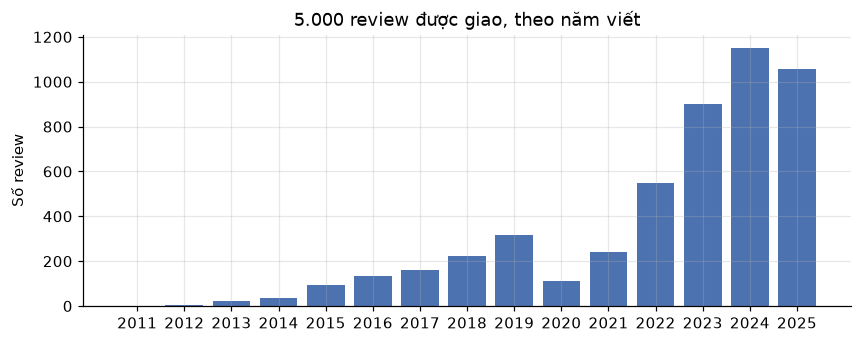

In [5]:
nam = ngay_review.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(nam.index.astype(str), nam.values, color="#4C72B0")
ax.set_title("5.000 review được giao, theo năm viết")
ax.set_ylabel("Số review")
plt.show()

Ba phần tư số review được viết từ năm 2022 trở lại đây, và biểu đồ có một chỗ lõm rõ ở năm 2020, lúc du lịch gần như ngừng vì đại dịch.
Từ năm 2019 đến 2025, mỗi năm có đủ review để so sánh cảm xúc giữa các năm. Còn các năm từ 2011 đến 2015 chỉ có vài chục review mỗi năm,
quá ít để rút ra kết luận.

## 3. Độ dài và định dạng của nội dung review

In [6]:
reviews = reviews_nhom[moc_gia].join(phan_cong_reviews.set_index("review_id")[["llm_sample", "human_sample"]])
reviews["do_dai"] = reviews["comments"].str.len()
reviews["co_html"] = reviews["comments"].str.contains("<br", regex=False)
# [^\x00-\x7F] khớp mọi ký tự ngoài bảng mã ASCII; .str.contains chạy trên cả cột (Bài 7).
reviews["co_ky_tu_ngoai_ascii"] = reviews["comments"].str.contains(r"[^\x00-\x7F]", regex=True)

print(reviews["do_dai"].describe(percentiles=[0.05, 0.5, 0.95]).round(0).to_string())
print(f"\nCó thẻ <br/>               : {reviews['co_html'].sum()} review ({reviews['co_html'].mean():.0%})")
print(f"Có ký tự ngoài ASCII       : {reviews['co_ky_tu_ngoai_ascii'].sum()} review")

# In 3 review mẫu để đọc bằng mắt; vòng lặp chỉ qua 3 dòng.
for review_id in reviews.sample(3, random_state=cau_hinh["seed"]).index:
    print(f"\n— review {review_id} ({reviews.at[review_id, 'date']}):")
    print("  " + reviews.at[review_id, "comments"][:300].replace("\n", " "))

count    5000.0
mean      275.0
std       160.0
min        64.0
5%        106.0
50%       229.0
95%       607.0
max      1003.0

Có thẻ <br/>               : 1142 review (23%)
Có ký tự ngoài ASCII       : 1267 review

— review 1139081174096319971 (2024-04-20):
  The room, was pretty much like an independent studio, very nice and exactly as described and looked in the photos. Denize was very helpful and made the check in process  very easy. I would certainly recommend this room.

— review 1418035176468262467 (2025-05-10):
  Deepak’s house is located in a quiet and nice neighborhood, walkable to high street. The place is clean, tidy and comfortable. Deepak and his family have been very helpful and nice to me. Thanks Deepak.

— review 1240528601100852727 (2024-09-07):
  We just stopped at Alex’s for one night after a long flight before heading off home early so it was what we needed. Very clean , great master bedroom with supper comfy bed. Sofa bed,  small for two but still comfy. Just th

Review ngắn nhất cũng dài 64 ký tự, nghĩa là trong bộ này không có review cụt kiểu "Great!" hay "Good". Dữ liệu không cho biết vì sao không có
review ngắn trong danh sách phân công. Trong khi đó, cột `%_review_duoi_64_ky_tu` ở mục 1 cho thấy khoảng 17,5% review của toàn London ở mốc cuối
ngắn hơn 64 ký tự. Như vậy mẫu của nhóm không đại diện cho nhóm review rất ngắn này. Điều đó có lợi cho LLM, vì mỗi review đều đủ ngữ cảnh để
tìm khía cạnh, nhưng cần được ghi rõ khi suy rộng kết quả.

Khoảng một phần tư số review chứa thẻ `<br/>`, là thẻ xuống dòng của HTML, đôi khi đi kèm ký tự `\r`. Thẻ này sẽ làm sai kết quả đếm từ khóa của
baseline (phương pháp đối chứng chỉ dựa vào từ khóa, không dùng LLM), và gây khó đọc khi trích review vào báo cáo. Người khảo sát đề xuất thay thẻ
này bằng khoảng trắng ở bước làm sạch, đồng thời giữ lại cột nội dung gốc.

## 4. Ngôn ngữ của review

Đề yêu cầu LLM xác định ngôn ngữ của từng review. Trước khi trông vào LLM, ta thử một phép đếm đơn giản: Review có chứa từ tiếng Anh thông dụng
nào không, và các ký tự ngoài bảng mã ASCII là những ký tự gì.

In [7]:
TU_TIENG_ANH = r"\b(the|and|was|very|great|we|is|a|to|in)\b"
so_tu_tieng_anh = reviews["comments"].str.lower().str.count(TU_TIENG_ANH)   # Đếm từ trên cả cột (Bài 7)
print("Review không có từ tiếng Anh thông dụng nào:", int((so_tu_tieng_anh == 0).sum()))
# In tối đa 5 review để đọc bằng mắt; vòng lặp chỉ qua các dòng kết quả.
for noi_dung in reviews.loc[so_tu_tieng_anh == 0, "comments"].head(5):
    print("  ·", noi_dung[:110])

# findall tách mọi ký tự ngoài ASCII của từng review thành một danh sách,
# explode đưa mỗi ký tự thành một dòng, rồi value_counts đếm (Bài 7, Bài 4).
(
    reviews["comments"]
    .str.findall(r"[^\x00-\x7F]")
    .explode()
    .value_counts()
    .head(12)
    .rename_axis("ky_tu")
    .reset_index(name="so_lan")
)

Review không có từ tiếng Anh thông dụng nào: 1
  · It’s been so lovely staying at Thaiani‘s! Central London but so quiet! Loved it!


,ky_tu,so_lan
0,’,1575
1,—,69
2,️,57
3,…,34
4,⭐,31
5,😊,26
6,“,22
7,👍,20
8,”,19
9,é,18


Chỉ đúng một review không chứa từ nào trong danh sách, và đọc lên thì nó vẫn là tiếng Anh, chỉ ngắn và có nhiều dấu chấm than. Các ký tự ngoài
ASCII chủ yếu là dấu nháy cong `’`, gạch dài, dấu ba chấm và emoji, không phải chữ của một ngôn ngữ khác.

Phép dò này chỉ cho biết không có dấu hiệu rõ của ngôn ngữ khác, chứ chưa đo được tỷ lệ ngôn ngữ. Một review viết bằng tiếng Pháp nhưng có
chữ "a" hay "the" vẫn có thể lọt qua. Nhóm vẫn cần một cách xác định ngôn ngữ đáng tin hơn (do LLM trả về và được kiểm lại trên 100 nhãn tay).
Nếu kết quả cho thấy gần như toàn bộ là tiếng Anh, accuracy của trường `language` sẽ cao gần như mặc nhiên, nên báo cáo nên ghi rõ số review
không phải tiếng Anh và xem riêng kết quả trên những review đó.

## 5. So sánh mẫu LLM và mẫu nhãn tay với toàn bộ 5.000 review

In [8]:
def tom_tat(nhom: pd.DataFrame) -> pd.Series:
    """Tính vài chỉ số mô tả để so các tập review với nhau."""
    nam_viet = pd.to_datetime(nhom["date"]).dt.year
    return pd.Series({
        "so_review": len(nhom),
        "so_listing": nhom["listing_id"].nunique(),
        "do_dai_trung_vi": nhom["do_dai"].median(),
        "%_viet_tu_2022": round(100 * (nam_viet >= 2022).mean(), 1),
        "%_co_html": round(100 * nhom["co_html"].mean(), 1),
    })

pd.DataFrame({
    "5.000 được giao": tom_tat(reviews),
    "1.000 mẫu LLM": tom_tat(reviews.loc[reviews["llm_sample"] == "True"]),
    "100 nhãn tay": tom_tat(reviews.loc[reviews["human_sample"] == "True"]),
})

,5.000 được giao,1.000 mẫu LLM,100 nhãn tay
so_review,5000.0,1000.0,100.0
so_listing,701.0,375.0,85.0
do_dai_trung_vi,229.0,232.0,238.0
%_viet_tu_2022,73.1,71.9,70.0
%_co_html,22.8,22.8,24.0


Ba tập review có độ dài, năm viết và tỷ lệ chứa HTML tương tự nhau. Sự tương tự này chưa chứng minh rằng hai tập con được rút ngẫu nhiên, và
càng chưa cho biết chúng có cùng phân bố cảm xúc hay khía cạnh với 5.000 review. Ba đặc điểm trên chỉ cho thấy không có khác biệt lớn về hình thức.

Có thêm hai giới hạn cần nhớ. Thứ nhất, 1.000 review của mẫu LLM chỉ đến từ 375 listing, còn 100 nhãn tay chỉ đến từ 85 listing. Thứ hai, 100 là
cỡ mẫu nhỏ: Mỗi review chỉ chiếm 1 điểm phần trăm, nên chỉ cần vài review được gán khác đi là accuracy đã đổi vài điểm. Vì thế, nếu LLM và baseline
chỉ chênh nhau vài điểm trên 100 review, chênh lệch đó cần được diễn giải thận trọng, kèm số review đúng và sai cụ thể của mỗi bên.

## 6. Tần suất nhắc tới từng khía cạnh

Baseline không dùng LLM thường dựa trên từ khóa. Ô dưới đây đếm tỷ lệ review chứa từ khóa của từng khía cạnh trong config, để biết khía cạnh nào
sẽ có đủ dữ liệu cho việc tính precision và recall.

**Cách đọc biểu đồ.** Mỗi thanh là một khía cạnh trong config. Độ dài thanh là phần trăm trong 5.000 review có chứa ít nhất một từ khóa của khía cạnh đó, và con số ở cuối thanh là giá trị chính xác. Một review có thể nhắc tới nhiều khía cạnh cùng lúc, nên cộng các thanh lại sẽ vượt quá 100%. Trục ngang được giữ cố định từ 0 đến 100 để độ dài mỗi thanh so được trực tiếp với toàn bộ số review.

Khía cạnh trong config chưa có từ khóa: không có


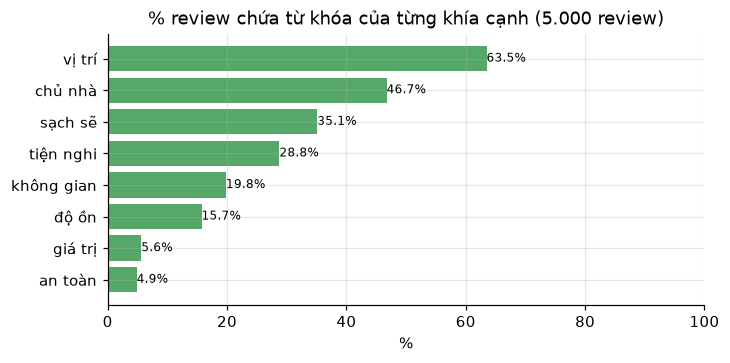

In [9]:
TU_KHOA_KHIA_CANH = {
    "vị trí": r"location|located|close to|walk|tube|station",
    "sạch sẽ": r"clean|spotless|tidy|dirty",
    "chủ nhà": r"host|responsive|welcoming|helpful",
    "giá trị": r"value|price|worth|expensive",
    "tiện nghi": r"kitchen|wifi|shower|bed|amenit",
    "độ ồn": r"quiet|nois|loud",
    "an toàn": r"safe|secure|unsafe",
    "không gian": r"spacious|space|roomy|small|cramped",
}
# Đối chiếu với danh sách khía cạnh trong config để không bỏ sót khía cạnh nào.
cac_khia_canh_config = cau_hinh["llm"]["aspects"]
print("Khía cạnh trong config chưa có từ khóa:", sorted(set(cac_khia_canh_config) - set(TU_KHOA_KHIA_CANH)) or "không có")

noi_dung_thuong = reviews["comments"].str.lower()
# Vòng lặp qua các khía cạnh; mỗi lần .str.contains chạy trên cả 5.000 review (Bài 7).
ti_le_khia_canh = pd.Series({
    khia_canh: noi_dung_thuong.str.contains(mau, regex=True).mean() * 100
    for khia_canh, mau in TU_KHOA_KHIA_CANH.items()
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(ti_le_khia_canh.index, ti_le_khia_canh.values, color="#55A868")
ax.bar_label(ax.containers[0], fmt="%.1f%%", fontsize=8)   # Ghi giá trị lên từng thanh (Bài 12)
ax.set(title="% review chứa từ khóa của từng khía cạnh (5.000 review)", xlabel="%", xlim=(0, 100))
plt.show()

Theo phép dò này, chỉ có vị trí xuất hiện trong hơn một nửa số review (khoảng 63,5%). Chủ nhà và sạch sẽ đứng sau, với khoảng 46,7% và 35,1%,
rồi tới tiện nghi, không gian và độ ồn. An toàn và giá trị hiếm nhất, mỗi khía cạnh chỉ khoảng 5%. Với các khía cạnh hiếm, 100 nhãn tay có thể
chỉ chứa dăm ba trường hợp. Số đó đủ để thấy LLM sai ở đâu, nhưng chưa đủ để tin vào một con số F1.

Cần nhớ rằng các con số này phụ thuộc vào bộ từ khóa tự chọn, nên chỉ dùng để ước lượng thứ tự, không phải tỷ lệ thật. Từ khóa còn có một giới hạn
khác: Nó chỉ cho biết khía cạnh được nhắc tới, chứ không cho biết đó là lời khen hay lời chê. Chẳng hạn câu "not very clean" vẫn khớp với từ khóa
`clean`, còn "small" có thể là lời chê không gian hoặc chỉ là một mô tả. Đây là loại lỗi mà LLM được kỳ vọng xử lý tốt hơn, và cũng là loại lỗi
nên có mặt trong phần phân tích lỗi.

## 7. Ước lượng thô số token

Đề yêu cầu ước tính chi phí nếu xử lý toàn bộ review của London. LLM tính phí theo token, là đơn vị nhỏ mà mô hình chia văn bản ra để xử lý. Với
tiếng Anh, có thể ước chừng 4 ký tự tương ứng 1 token.

In [10]:
KY_TU_MOI_TOKEN = 4   # Xấp xỉ cho tiếng Anh; cần thay bằng số token thật do API trả về sau khi chạy thử.
mau_llm = reviews.loc[reviews["llm_sample"] == "True"]
so_review_thanh_pho = thong_tin_doc[moc_gia]["review_thanh_pho"]

pd.Series({
    "token trung bình / review của mẫu LLM": round(mau_llm["do_dai"].mean() / KY_TU_MOI_TOKEN),
    "token của cả mẫu LLM (1.000 review)": round(mau_llm["do_dai"].sum() / KY_TU_MOI_TOKEN),
    f"token của toàn thành phố ({so_review_thanh_pho:,} review)": round(thong_tin_doc[moc_gia]["tong_ky_tu_comments"] / KY_TU_MOI_TOKEN),
}, name="token xấp xỉ (chỉ phần comments)").to_frame()

,token xấp xỉ (chỉ phần comments)
token trung bình / review của mẫu LLM,69
token của cả mẫu LLM (1.000 review),69221
"token của toàn thành phố (2,241,353 review)",137239188


Con số của mẫu LLM được tính trực tiếp trên 1.000 review của mẫu. Con số của toàn thành phố được tính từ tổng số ký tự của mọi review ở mốc cuối
(đếm ở mục 1), không suy ra từ mẫu. Hai cách tính khác nhau có lý do: Review của nhóm dài hơn mức chung của thành phố, vì mẫu không có review
ngắn hơn 64 ký tự, nên nếu lấy độ dài trung bình của mẫu nhân cho cả London thì ước tính sẽ cao hơn thực tế.

Cả hai con số mới chỉ là token đầu vào cho phần nội dung review, chưa phải chi phí API. Chúng chưa tính phần hướng dẫn trong prompt (đoạn chỉ dẫn
gửi kèm mỗi lần gọi LLM), vốn lặp lại ở mỗi lượt gửi, và chưa tính token đầu ra, tức đoạn JSON mà mô hình trả về. Token đầu ra có thể ngang hoặc
nhiều hơn đầu vào, vì mỗi review sinh ra một đối tượng JSON riêng. Cách ước tính chắc chắn nhất là chạy thử vài lượt, đọc số token mà API trả về,
rồi nhân với giá của mô hình và số review.

Notebook 05 chuyển sang khía cạnh không gian, đặt các quận và vùng A01–A08 lên cùng một bản đồ.